In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from keras.models import Sequential
from keras.layers import LSTM, Dense, Dropout
from keras.callbacks import History
import math



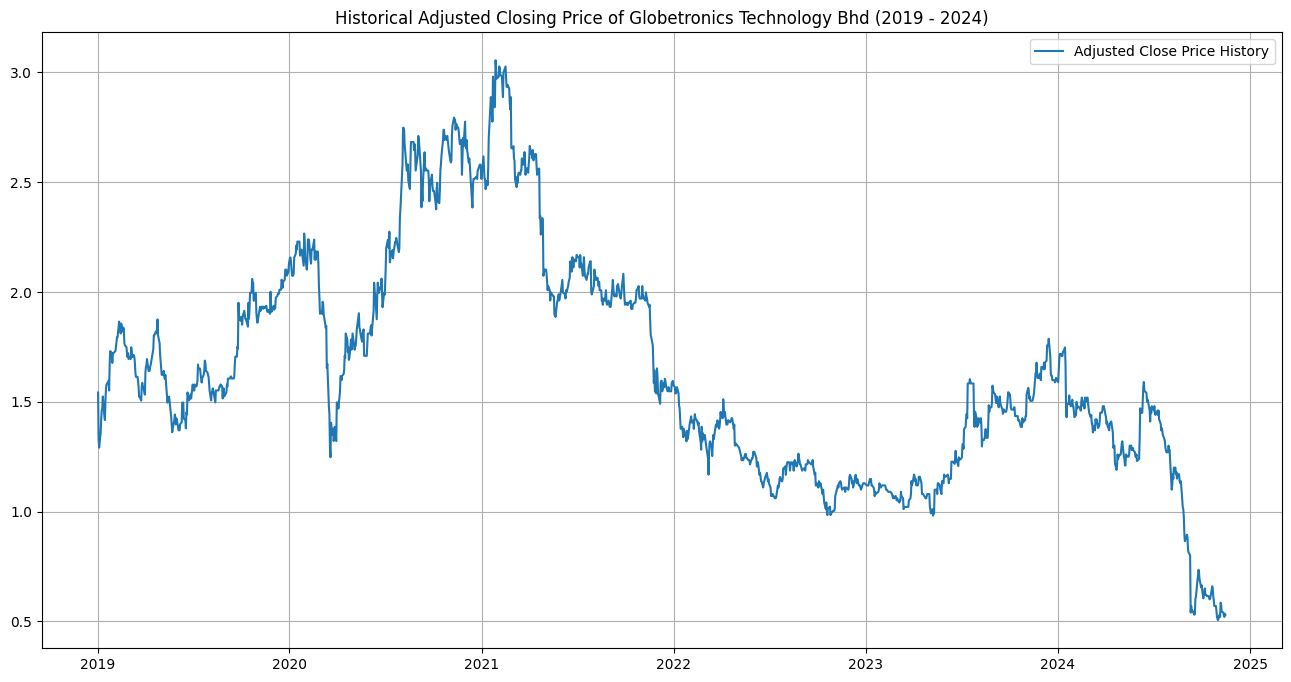

In [2]:
df = pd.read_csv("C:\\Users\\Faiz\\Downloads\\DSP 1\\5 years dataset.csv")
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)
df = df.sort_index()
plt.figure(figsize=(16, 8))
plt.plot(df['Adj Close'], label='Adjusted Close Price History')
plt.title("Historical Adjusted Closing Price of Globetronics Technology Bhd (2019 - 2024)")
plt.legend()
plt.grid(True)
plt.show()

<Figure size 1600x800 with 0 Axes>

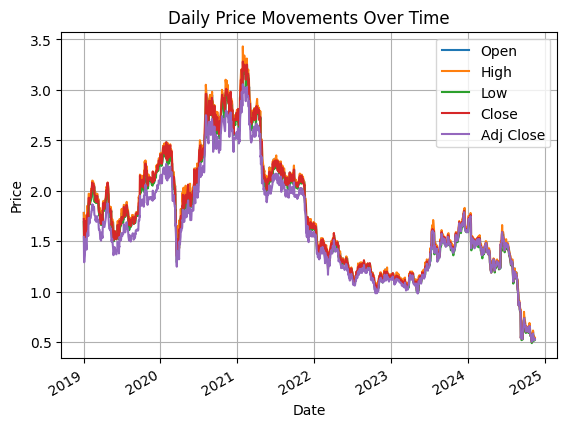

In [3]:
plt.figure(figsize=(16,8))
df[['Open', 'High', 'Low', 'Close', 'Adj Close']].plot()
plt.title("Daily Price Movements Over Time")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.show()


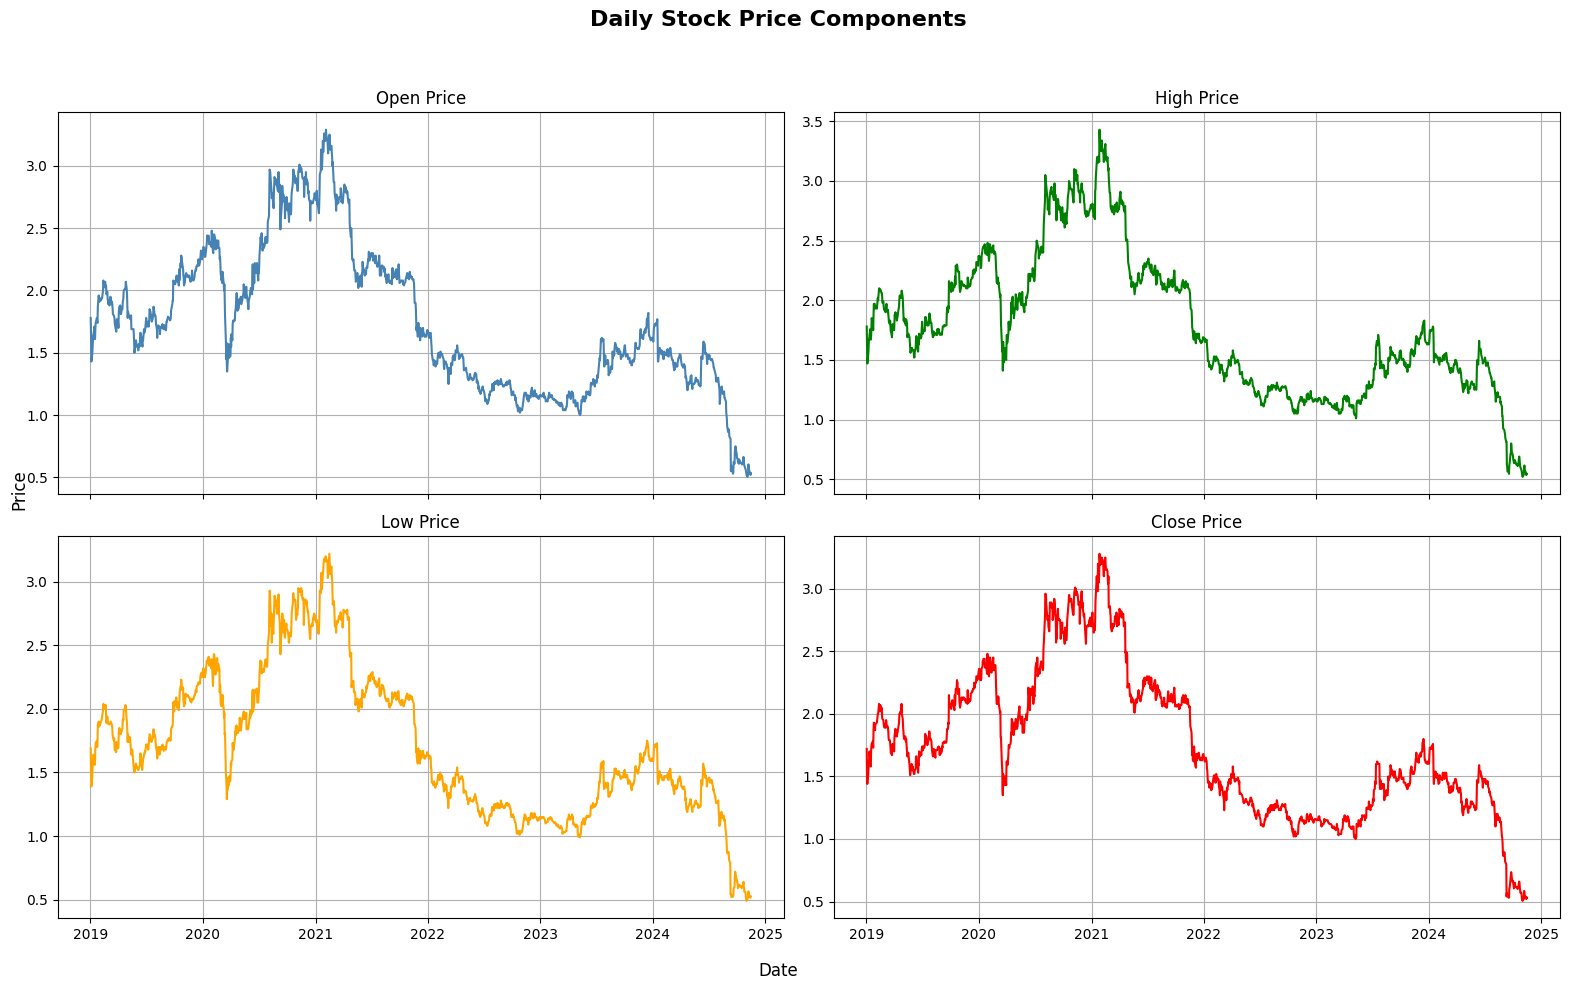

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(16, 10), sharex=True)

axs[0, 0].plot(df.index, df['Open'], color='steelblue')
axs[0, 0].set_title('Open Price')
axs[0, 0].grid(True)

axs[0, 1].plot(df.index, df['High'], color='green')
axs[0, 1].set_title('High Price')
axs[0, 1].grid(True)

axs[1, 0].plot(df.index, df['Low'], color='orange')
axs[1, 0].set_title('Low Price')
axs[1, 0].grid(True)

axs[1, 1].plot(df.index, df['Close'], color='red')
axs[1, 1].set_title('Close Price')
axs[1, 1].grid(True)

fig.suptitle('Daily Stock Price Components', fontsize=16, weight='bold')
fig.supxlabel('Date')
fig.supylabel('Price')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


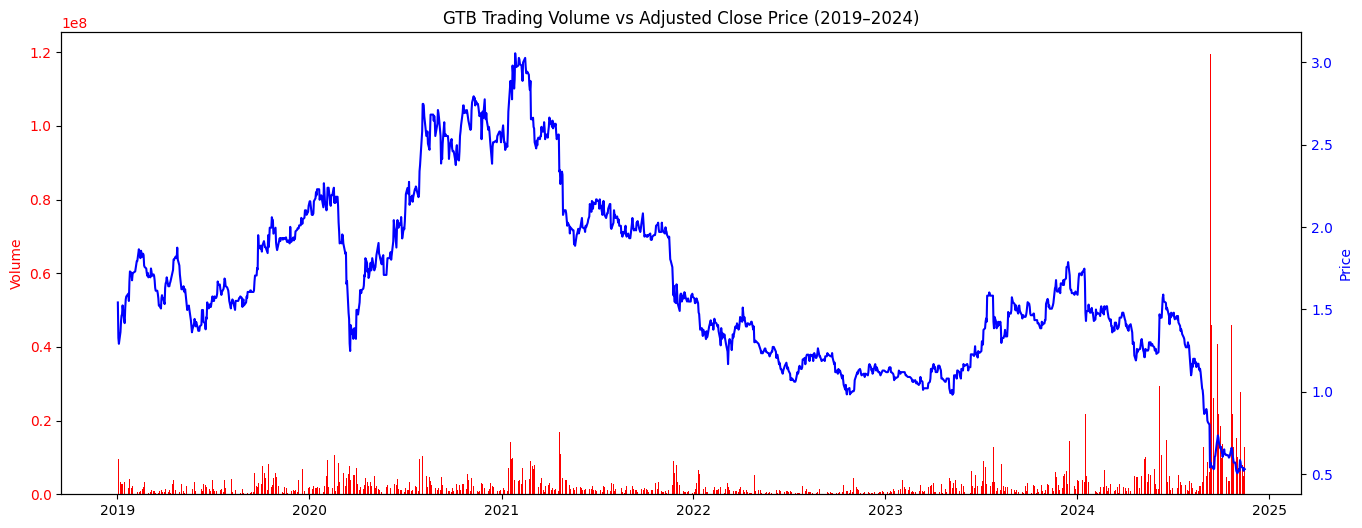

In [ ]:
fig, ax1 = plt.subplots(figsize=(16, 6))

ax1.bar(df.index, df['Volume'], color='red', label='Volume')
ax1.set_ylabel('Volume', color='red')
ax1.tick_params(axis='y', labelcolor='red')

ax2 = ax1.twinx()
ax2.plot(df.index, df['Adj Close'], color='blue', label='Adj Close Price')
ax2.set_ylabel('Price', color='blue')
ax2.tick_params(axis='y', labelcolor='blue')

plt.title('GTB Trading Volume vs Adjusted Close Price (2019–2024)')
plt.show()


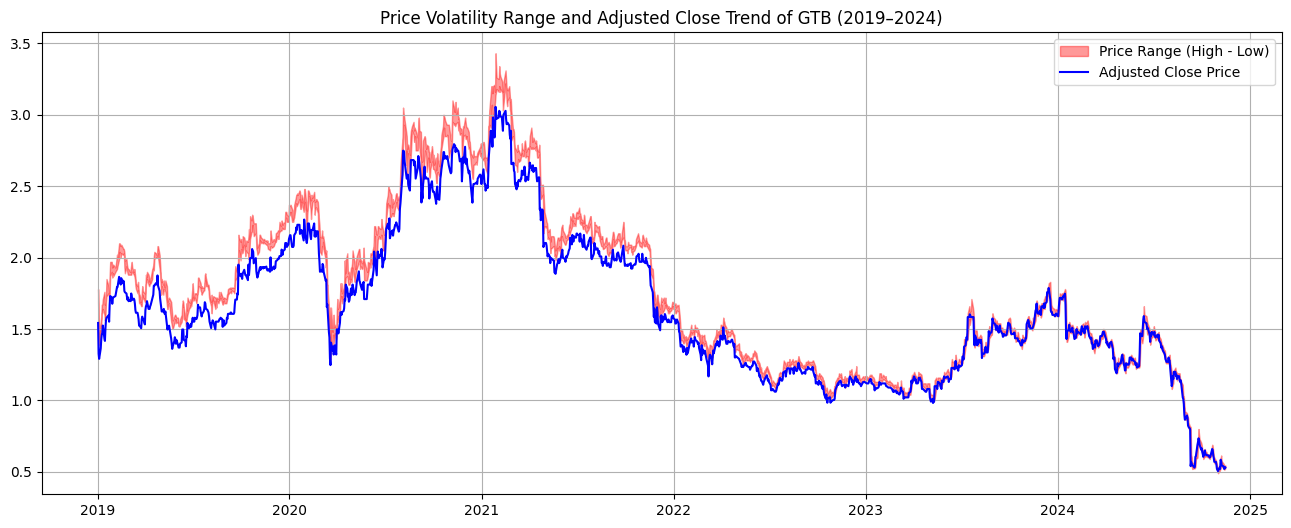

In [6]:
plt.figure(figsize=(16, 6))
plt.fill_between(df.index, df['Low'], df['High'], color='red', alpha=0.4, label='Price Range (High - Low)')
plt.plot(df.index, df['Adj Close'], color='blue', label='Adjusted Close Price')
plt.title("Price Volatility Range and Adjusted Close Trend of GTB (2019–2024)")
plt.legend()
plt.grid(True)
plt.show()


In [7]:
import plotly.graph_objects as go

fig = go.Figure(data=[go.Candlestick(
    x=df.index,
    open=df['Open'],
    high=df['High'],
    low=df['Low'],
    close=df['Close']
)])
fig.update_layout(title='Candlestick Chart', xaxis_title='Date', yaxis_title='Price')
fig.show()


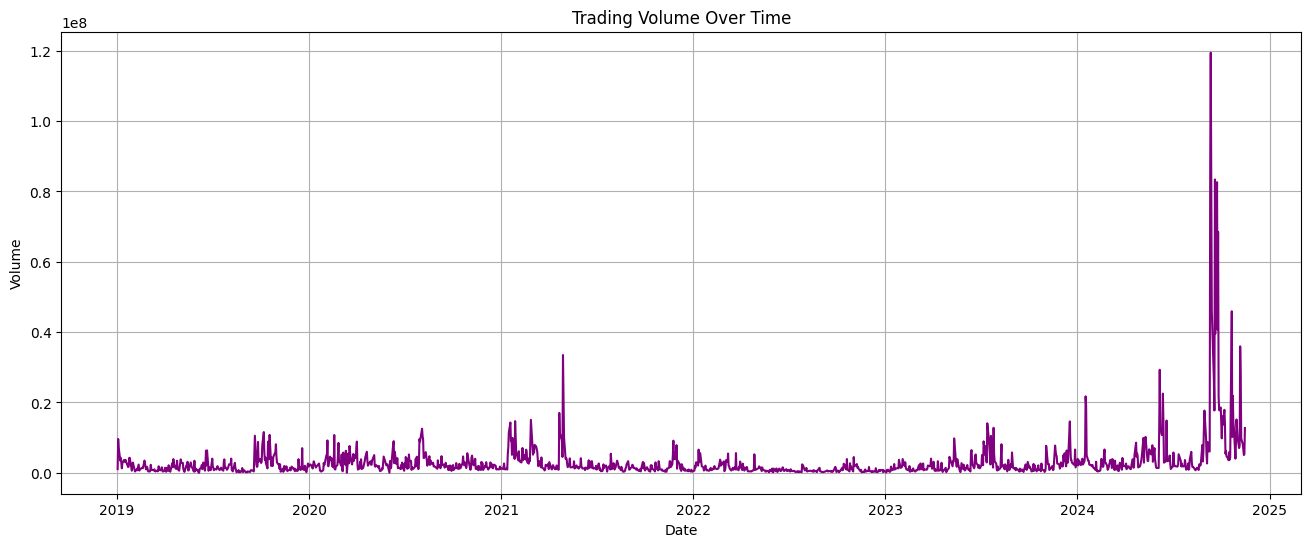

In [8]:
plt.figure(figsize=(16,6))
plt.plot(df['Volume'], color='purple')
plt.title('Trading Volume Over Time')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.grid(True)
plt.show()


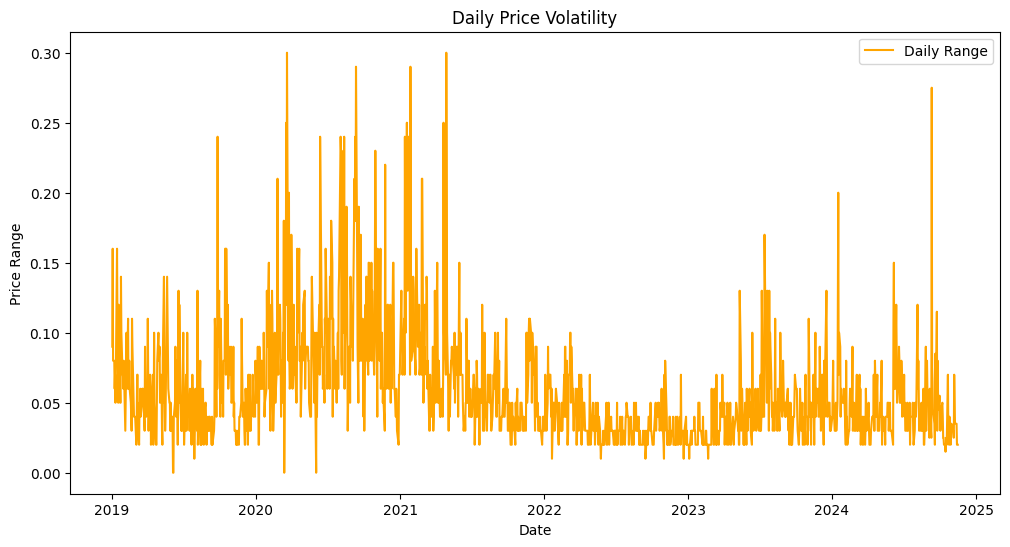

In [9]:
df['Range'] = df['High'] - df['Low']
plt.figure(figsize=(12,6))
plt.plot(df['Range'], label='Daily Range', color='orange')
plt.title("Daily Price Volatility")
plt.xlabel("Date")
plt.ylabel("Price Range")
plt.legend()
plt.show()


In [10]:
df.head()

,Adj Close,Close,High,Low,Open,Volume,Range
Date,,,,,,,
2019-01-02 00:00:00+00:00,1.542200,1.72,1.78,1.69,1.78,1027500,0.09
2019-01-03 00:00:00+00:00,1.327009,1.48,1.64,1.48,1.64,9594500,0.16
2019-01-04 00:00:00+00:00,1.291144,1.44,1.47,1.39,1.43,7220200,0.08
2019-01-07 00:00:00+00:00,1.362874,1.52,1.55,1.47,1.49,3439900,0.08
2019-01-08 00:00:00+00:00,1.425638,1.59,1.59,1.53,1.54,4228500,0.06


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1441 entries, 2019-01-02 00:00:00+00:00 to 2024-11-15 00:00:00+00:00
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Adj Close  1441 non-null   float64
 1   Close      1441 non-null   float64
 2   High       1441 non-null   float64
 3   Low        1441 non-null   float64
 4   Open       1441 non-null   float64
 5   Volume     1441 non-null   int64  
 6   Range      1441 non-null   float64
dtypes: float64(6), int64(1)
memory usage: 90.1 KB


In [12]:
data = df[['Adj Close']].copy()
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

In [13]:
train_size = int(len(scaled_data) * 0.8)
train_data = scaled_data[:train_size]
valid_data = scaled_data[train_size - 60:]

In [14]:
x_train, y_train = [], []
for i in range(60, len(train_data)):
    x_train.append(train_data[i-60:i, 0])
    y_train.append(train_data[i, 0])

x_train, y_train = np.array(x_train), np.array(y_train)
x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))

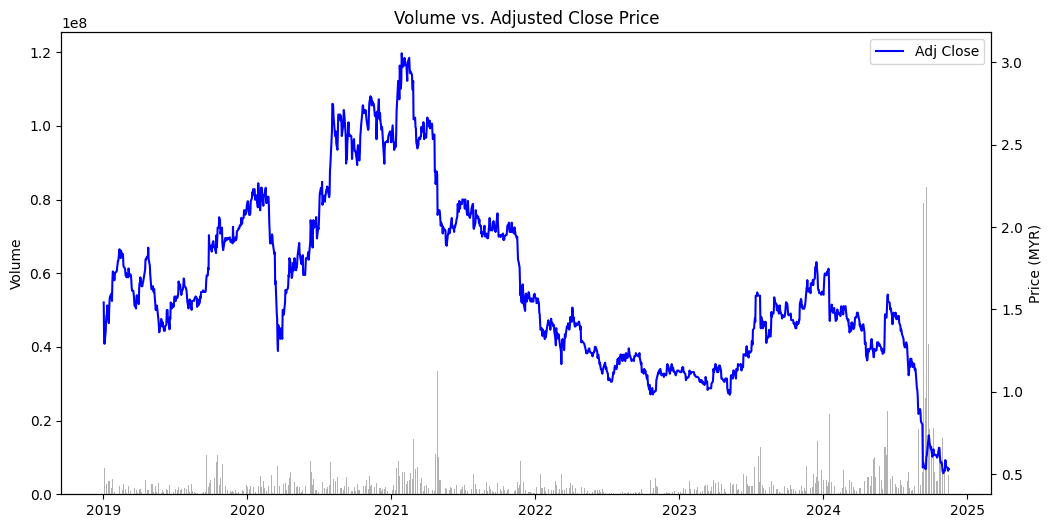

In [15]:
fig, ax1 = plt.subplots(figsize=(12,6))
ax1.bar(df.index, df['Volume'], color='grey', alpha=0.6, label='Volume')
ax1.set_ylabel('Volume')
ax2 = ax1.twinx()
ax2.plot(df.index, df['Adj Close'], color='blue', label='Adj Close')
ax2.set_ylabel('Price (MYR)')
plt.title("Volume vs. Adjusted Close Price")
plt.legend()
plt.show()

In [ ]:
def build_and_train_model(epochs):
    model = Sequential()
    model.add(LSTM(units=150, return_sequences=True, input_shape=(x_train.shape[1], 1)))
    model.add(Dropout(0.2))
    model.add(LSTM(units=150))
    model.add(Dropout(0.2))
    model.add(Dense(1))

    model.compile(loss='mean_squared_error', optimizer='adam')
    history = model.fit(
        x_train, y_train,
        epochs=epochs,
        batch_size=16,
        verbose=0,
        validation_split=0.2
    ) 
    return history,model



Training for 20 epochs...



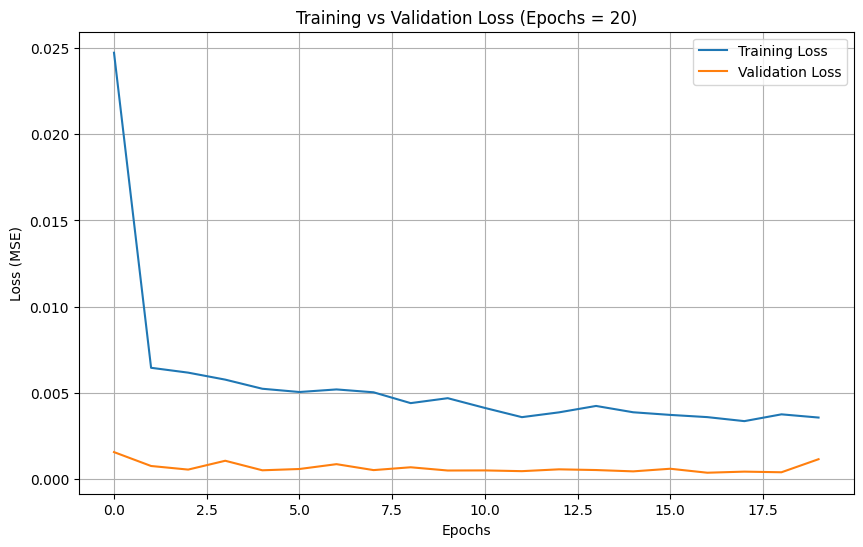


Training for 30 epochs...



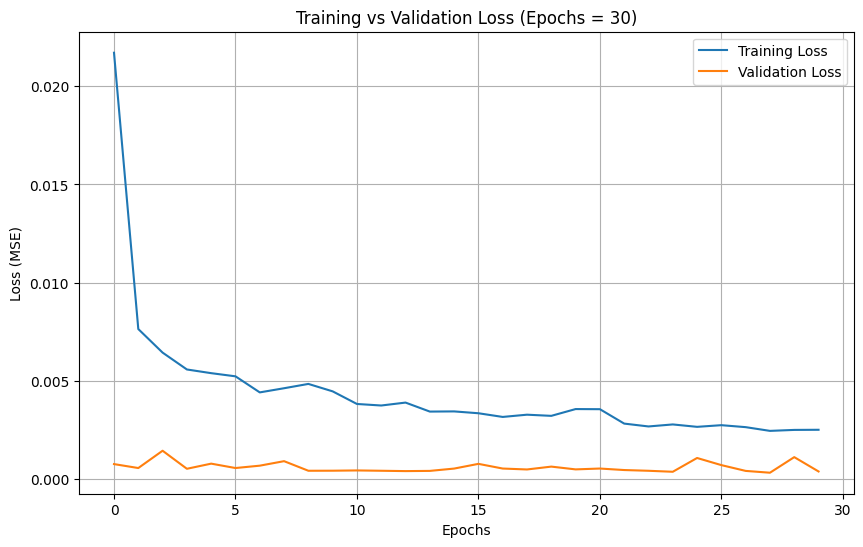


Training for 40 epochs...



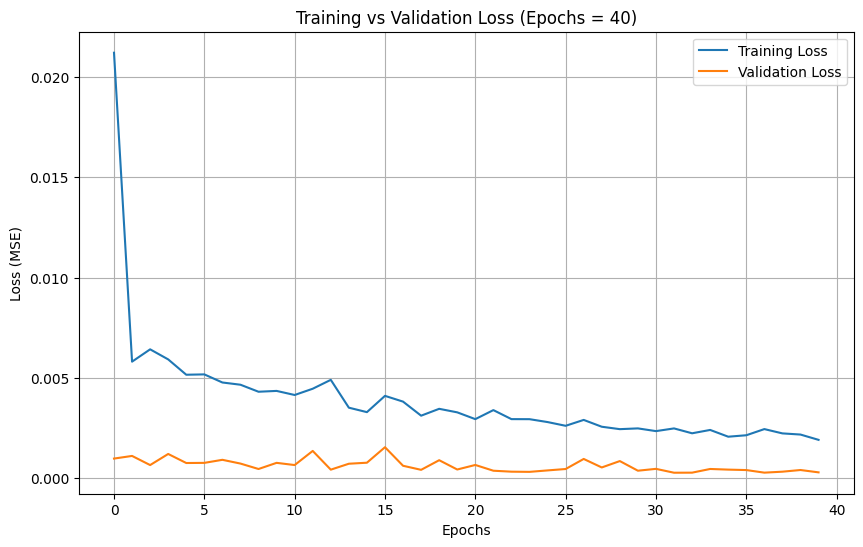


Training for 50 epochs...



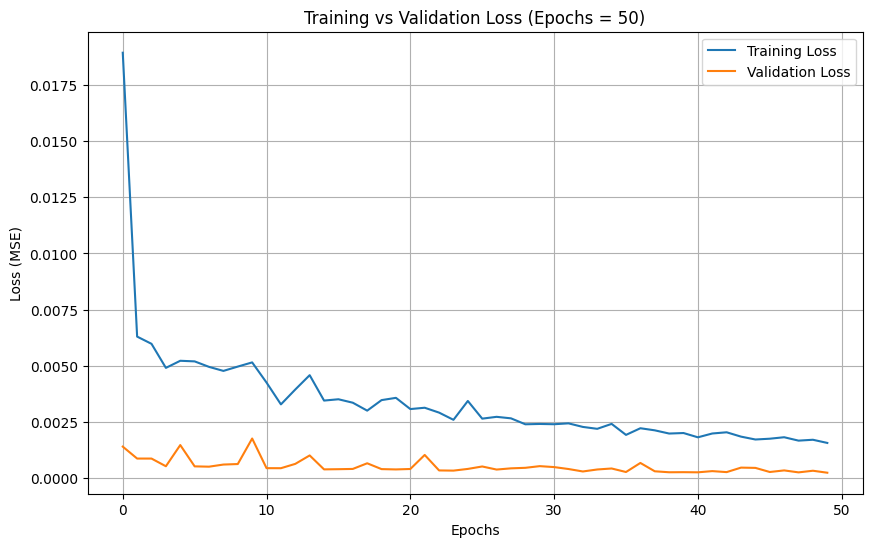

In [ ]:
epoch_list = [20, 30, 40, 50]

for ep in epoch_list:
    print(f"\nTraining for {ep} epochs...\n")
    history, model = build_and_train_model(ep) 
    
    plt.figure(figsize=(10, 6))
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'Training vs Validation Loss (Epochs = {ep})')
    plt.xlabel('Epochs')
    plt.ylabel('Loss (MSE)')
    plt.legend()
    plt.grid(True)
    plt.show()


In [21]:
x_test = []
for i in range(60, len(valid_data)):
    x_test.append(valid_data[i-60:i, 0])

x_test = np.array(x_test)
x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))

In [22]:
predicted_price = model.predict(x_test)
predicted_price = scaler.inverse_transform(predicted_price)

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step


In [23]:
real_valid = data[train_size:]
real_valid['Predictions'] = predicted_price

C:\Users\Faiz\AppData\Local\Temp\ipykernel_23172\1585062917.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



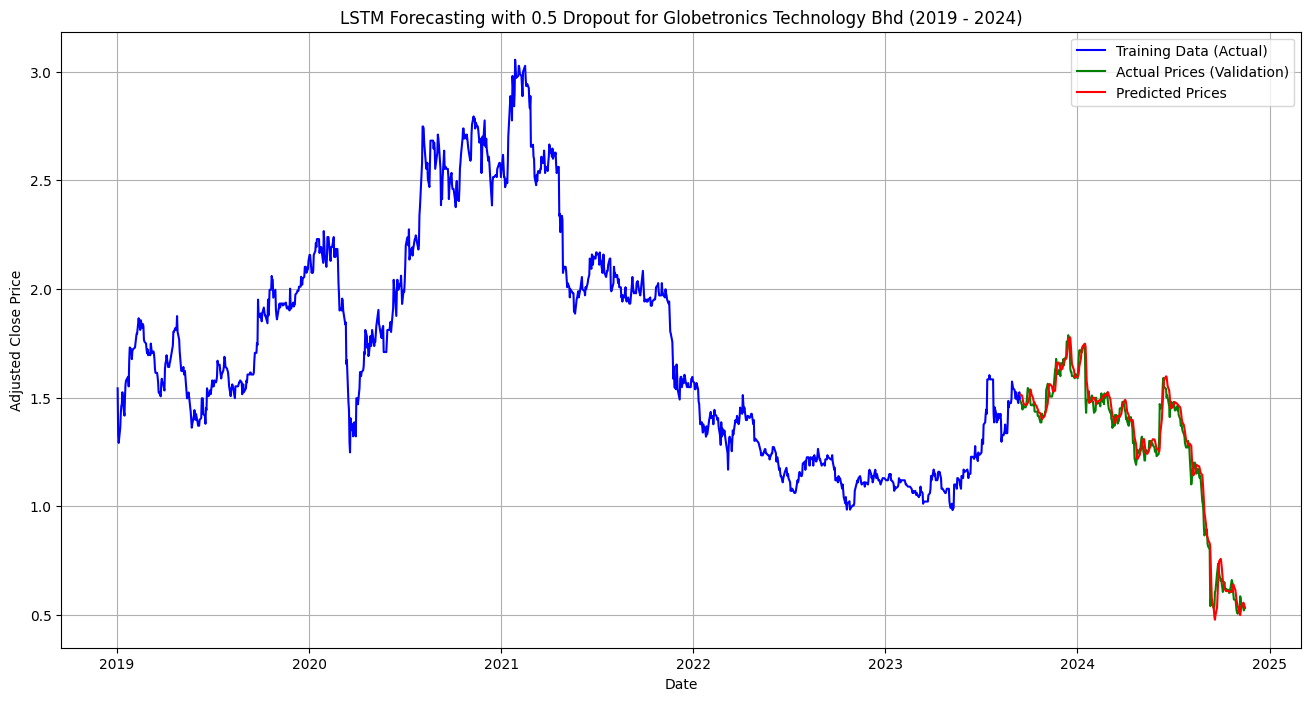

In [ ]:
plt.figure(figsize=(16, 8))
plt.plot(data[:train_size], label="Training Data (Actual)", color='blue')
plt.plot(real_valid['Adj Close'], label="Actual Prices (Validation)", color='green')
plt.plot(real_valid['Predictions'], label="Predicted Prices", color='red')
plt.title("LSTM Forecasting with 0.2 Dropout for Globetronics Technology Bhd (2019 - 2024)")
plt.xlabel("Date")
plt.ylabel("Adjusted Close Price")
plt.legend()
plt.grid(True)
plt.show()

In [25]:
mse = mean_squared_error(real_valid['Adj Close'], real_valid['Predictions'])
rmse = math.sqrt(mse)
mae = mean_absolute_error(real_valid['Adj Close'], real_valid['Predictions'])
mape = np.mean(np.abs((real_valid['Adj Close'] - real_valid['Predictions']) / real_valid['Adj Close'])) * 100

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")

Mean Squared Error (MSE): 0.0033
Root Mean Squared Error (RMSE): 0.0576
Mean Absolute Error (MAE): 0.0413
Mean Absolute Percentage Error (MAPE): 3.80%


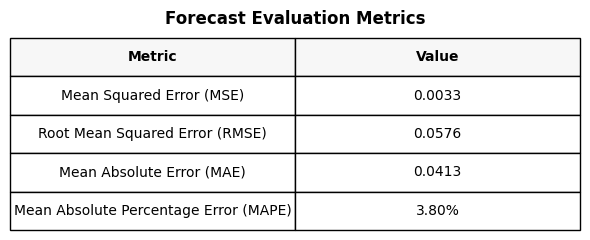

In [26]:
import matplotlib.pyplot as plt
from matplotlib.table import Table

# Calculate metrics
mse = mean_squared_error(real_valid['Adj Close'], real_valid['Predictions'])
rmse = math.sqrt(mse)
mae = mean_absolute_error(real_valid['Adj Close'], real_valid['Predictions'])
mape = np.mean(np.abs((real_valid['Adj Close'] - real_valid['Predictions']) / real_valid['Adj Close'])) * 100

# Create figure
fig, ax = plt.subplots(figsize=(6, 2.5))
ax.set_axis_off()

# Create table data
metrics_data = [
    ["Metric", "Value"],
    ["Mean Squared Error (MSE)", f"{mse:.4f}"],
    ["Root Mean Squared Error (RMSE)", f"{rmse:.4f}"],
    ["Mean Absolute Error (MAE)", f"{mae:.4f}"],
    ["Mean Absolute Percentage Error (MAPE)", f"{mape:.2f}%"]
]

# Create table
table = Table(ax, bbox=[0, 0, 1, 1])
n_rows = len(metrics_data)
n_cols = len(metrics_data[0])

# Add cells
for i in range(n_rows):
    for j in range(n_cols):
        table.add_cell(i, j, width=1/n_cols, height=1/n_rows, text=metrics_data[i][j],
                       loc='center', facecolor='#f7f7f7' if i == 0 else 'white', edgecolor='black')

# Set column and row labels bold
table.auto_set_font_size(False)
table.set_fontsize(10)
for (i, j), cell in table.get_celld().items():
    if i == 0:
        cell.set_text_props(weight='bold')

ax.add_table(table)
plt.title("Forecast Evaluation Metrics", fontsize=12, weight='bold', pad=10)
plt.tight_layout()
plt.show()
